In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [48]:

DATA_URL = 'https://raw.githubusercontent.com/Motzemoere/Earth-System-Modelling/main/data/'

data_ger = pd.read_csv(DATA_URL + 'Data_swbm_Germany.csv')
data_spa = pd.read_csv(DATA_URL + 'Data_swbm_Spain.csv')
data_swe = pd.read_csv(DATA_URL + 'Data_swbm_Sweden.csv')

data = data_spa
data.head()

,time,longitude,latitude,snr_[MJ/m2],tp_[mm],ro_[m],sm_[m3/m3],le_[W/m2],t2m_[K],lai_[m2/m2],evi_[],ndvi_[]
0,2008-01-01,-3.625,38.625,1.626502,0.005948,6.938894e-18,0.237595,15.159672,276.25730,0.301092,0.144028,0.308848
1,2008-01-02,-3.625,38.625,0.460111,12.292146,3.118947e-06,0.255496,15.098058,280.40665,0.313950,0.145418,0.310403
2,2008-01-03,-3.625,38.625,2.494015,12.748878,3.820767e-06,0.297574,15.036444,280.50784,0.326808,0.146807,0.311957
3,2008-01-04,-3.625,38.625,1.190013,0.767430,1.054999e-07,0.306924,14.974831,278.68634,0.339666,0.148197,0.313512
4,2008-01-05,-3.625,38.625,2.741926,0.770978,1.571217e-07,0.306925,14.913217,280.58370,0.352524,0.149586,0.315067


In [49]:
def water_runoff_amount(soil_water, soil_capacity,soil_alpha, precipitation):
    #returns ratio of water in vs out of the soil
    ratio = (soil_water / soil_capacity)**soil_alpha
    runoff_amount = ratio * precipitation
    return runoff_amount

In [50]:
def calculate_evapotranspiration(beta_zero, soil_water, soil_capacity, gamma, radiation):
    if gamma > 0 and beta_zero <= 1:
        evapotranspiration_amount = (beta_zero * (soil_water / soil_capacity) ** gamma) * radiation
        return evapotranspiration_amount
    else:
        return "Gamma or Beta_0 out of range"       

In [51]:

def calculate_step(precipitation, soil_water, soil_capacity, alpha, gamma, beta_zero, radiation):
    runoff_amount = water_runoff_amount(soil_water, soil_capacity,alpha, precipitation)
    evapotranspiration = calculate_evapotranspiration(beta_zero, soil_water, soil_capacity, gamma, radiation)
    soil_water = soil_water + ( precipitation - evapotranspiration - runoff_amount)
    return runoff_amount, evapotranspiration, soil_water

In [52]:
def run_model(data, alpha, gamma, beta_zero, soil_capacity):
    # for collecting results
    results = []
    if results == []: #for first timestep
            soil_water = 0.9 * soil_capacity # was in slides

    for i in range(len(data)):
        precipitation =     data["tp_[mm]"][i]
        radiation =         data["snr_[mm]"][i]
        time =              data["time"][i]
        runoff_amount, evapotranspiration, soil_water = calculate_step(precipitation, soil_water, soil_capacity, alpha, gamma, beta_zero, radiation)
        r = { "runoff_amount" : runoff_amount,
                    "evapotranspiration" : evapotranspiration,
                    "soil_water" : soil_water,
                    "day" : time,
                    # "precipitation": precipitation, 
                    # "soil_capacity" : soil_capacity, 
                    # "alpha" : alpha, 
                    # "gamma" : gamma, 
                    # "beta_zero" : beta_zero
        }
        results.append(r)
    results_df = pd.DataFrame(results)
    results_df = results_df.set_index("day")
    return results_df

In [53]:
precipitation = data["tp_[mm]"]
soil_capacity = 420 # from slides [mm]
# c_s = 
alpha = 4 # from slides (runoff function shape)
gamma = 0.5 # from slides (ET function shape)
beta_zero = 0.8 # from slides (max of ET function)
radiation = data["snr_[mm]"] = data["snr_[MJ/m2]"]/2.26 # unit conversion to match precipitation
sm = data['sm_[m3/m3]'] * 1000
runoff = data['ro_[m]'] * 24000
le = data["le_[W/m2]"]* (86400 / 2260000)
snr = data['snr_[MJ/m2]'] * (1 / 2.26)

model_output = run_model(data, alpha, gamma, beta_zero, soil_capacity)
model_output.index = pd.to_datetime(model_output.index)
# print(model_output)

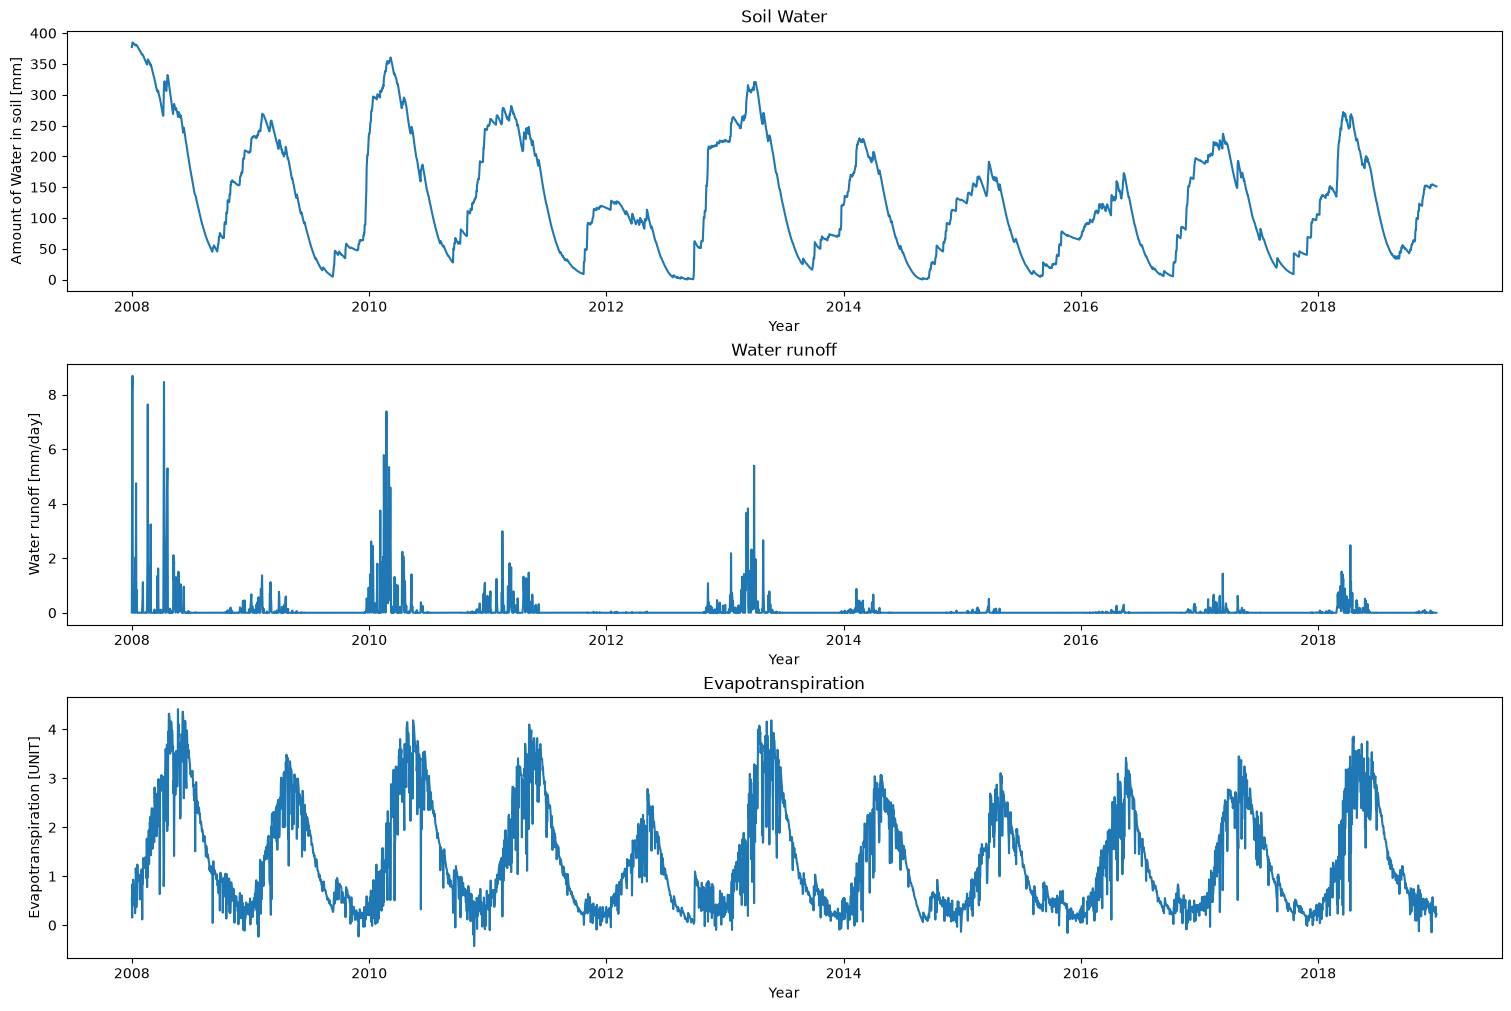

In [54]:
fig, axs = plt.subplots(3, 1, figsize = (15 ,10), constrained_layout=True)
axs[0].plot(model_output.index, model_output["soil_water"])
axs[0].set_title("Soil Water")
axs[0].set(xlabel = "Year", ylabel="Amount of Water in soil [mm]")
axs[1].plot(model_output.index, model_output["runoff_amount"])
axs[1].set_title("Water runoff")
axs[1].set(xlabel = "Year", ylabel="Water runoff [mm/day]")
axs[2].plot(model_output.index, model_output["evapotranspiration"])
axs[2].set_title("Evapotranspiration")
axs[2].set(xlabel = "Year", ylabel="Evapotranspiration [UNIT]");

In [55]:
def model_correlation(data, model_output):
    # Compute correlations between observations and model output
    
    corr_sm = np.corrcoef(sm, model_output['soil_water'])[0, 1]
    
    corr_ro = np.corrcoef(runoff, model_output['runoff_amount'])[0, 1]
    
    corr_et = np.corrcoef(le, model_output['evapotranspiration'])[0, 1]

    corr_sum = corr_sm + corr_ro + corr_et

    return {'sm': corr_sm, 'ro': corr_ro, 'et': corr_et, 'sum': corr_sum}

In [56]:
corrs = model_correlation(data, model_output)
print("Correlation between observed data and model outputs:\n")
print(f"Soil Moisture (sm):    {corrs['sm']:.3f}")
print(f"Runoff (ro):           {corrs['ro']:.3f}")
print(f"Evapotranspiration (et): {corrs['et']:.3f}")
print(f"\nSum of correlations:   {corrs['sum']:.3f}")

Correlation between observed data and model outputs:

Soil Moisture (sm):    0.759
Runoff (ro):           0.337
Evapotranspiration (et): 0.839

Sum of correlations:   1.935
